# Unit 9 — Membangun Model
**Kode unit:** J.62DMI00.013.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini mengeksekusi konfigurasi skenario dari Unit 8: melatih dan memvalidasi 3 baseline dan 5 algoritma dengan `TimeSeriesSplit`, memilih model terbaik dengan aturan yang sudah ditetapkan, melakukan *hyperparameter tuning*, mendiagnosis *overfitting*, lalu menyimpan model final beserta metadatanya. **Data uji tidak disentuh sama sekali di notebook ini.**

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

def to_json(obj, path):
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))

In [2]:
import time
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score

train = pd.read_csv(PROC / 'train.csv', parse_dates=['Date'])
with open(REP / 'model_scenarios.json', encoding='utf-8') as f:
    cfg = json.load(f)
FEATURES = cfg['features']
X, y = train[FEATURES], train.y
REGISTRY = {c.__name__: c for c in [DummyClassifier, LogisticRegression, DecisionTreeClassifier,
                                    RandomForestClassifier, GradientBoostingClassifier, SVC]}


def make_pipeline(spec, params=None):
    model = REGISTRY[spec['estimator']](**(params if params is not None else spec['params']))
    steps = [('scaler', StandardScaler())] if spec.get('scaling') else []
    return Pipeline(steps + [('model', model)])


tscv = TimeSeriesSplit(n_splits=cfg['cv']['n_splits'], gap=cfg['cv']['gap'])
SCORING = ['accuracy', 'f1_macro', 'roc_auc', 'precision_macro', 'recall_macro']
print(f'Data latih: {len(train):,} hari ({train.Date.min():%b %Y} – {train.Date.max():%b %Y}), {len(FEATURES)} fitur')
print(f'Validasi: {cfg["cv"]} | metrik utama: {cfg["primary_metric"]}')

Data latih: 3,148 hari (Mar 2010 – Jan 2023), 16 fitur
Validasi: {'method': 'TimeSeriesSplit', 'n_splits': 5, 'gap': 1} | metrik utama: f1_macro


## 1. Validasi silang semua skenario

In [3]:
def rule_scores(Xv, yv, col):
    pred = (Xv[col] > 0).astype(int)
    return {'accuracy': accuracy_score(yv, pred), 'f1_macro': f1_score(yv, pred, average='macro'),
            'roc_auc': roc_auc_score(yv, Xv[col]),
            'precision_macro': precision_score(yv, pred, average='macro', zero_division=0),
            'recall_macro': recall_score(yv, pred, average='macro', zero_division=0)}


rows, per_fold = [], {}
for spec in cfg['baselines'] + cfg['models']:
    t0 = time.time()
    if spec['estimator'].startswith('rule:'):
        col = spec['estimator'].split(':')[1]
        res = pd.DataFrame([rule_scores(X.iloc[va], y.iloc[va], col) for _, va in tscv.split(X)])
    else:
        cv = cross_validate(make_pipeline(spec), X, y, cv=tscv, scoring=SCORING)
        res = pd.DataFrame({k: cv[f'test_{k}'] for k in SCORING})
    per_fold[spec['id']] = res
    rows.append({'id': spec['id'], 'nama': spec['nama'], 'jenis': 'Baseline' if spec['id'].startswith('B') else 'Model',
                 **{f'{k}_mean': res[k].mean() for k in SCORING}, **{f'{k}_std': res[k].std() for k in SCORING},
                 'waktu_s': time.time() - t0})
cvres = pd.DataFrame(rows)
cvres.to_csv(REP / 'cv_results.csv', index=False)

show = cvres[['id', 'nama', 'jenis']].copy()
for k in ['accuracy', 'f1_macro', 'roc_auc', 'precision_macro', 'recall_macro']:
    show[k] = cvres[f'{k}_mean'].map('{:.3f}'.format) + ' ± ' + cvres[f'{k}_std'].map('{:.3f}'.format)
show['waktu (s)'] = cvres.waktu_s.round(1)
display(show)

,id,nama,jenis,accuracy,f1_macro,roc_auc,precision_macro,recall_macro,waktu (s)
0,B1,Mayoritas,Baseline,0.542 ± 0.020,0.352 ± 0.008,0.500 ± 0.000,0.271 ± 0.010,0.500 ± 0.000,0.1000
1,B2,Acak berstrata,Baseline,0.496 ± 0.016,0.492 ± 0.017,0.492 ± 0.017,0.492 ± 0.017,0.492 ± 0.017,0.1000
2,B3,Ikuti arah S&P 500,Baseline,0.595 ± 0.025,0.593 ± 0.024,0.630 ± 0.036,0.594 ± 0.024,0.594 ± 0.024,0.0000
3,S1,Logistic Regression,Model,0.602 ± 0.016,0.597 ± 0.015,0.633 ± 0.028,0.600 ± 0.015,0.598 ± 0.014,0.1000
4,S2,Decision Tree,Model,0.563 ± 0.019,0.563 ± 0.019,0.602 ± 0.032,0.568 ± 0.020,0.567 ± 0.020,0.1000
5,S3,Random Forest,Model,0.606 ± 0.023,0.602 ± 0.023,0.635 ± 0.029,0.603 ± 0.022,0.603 ± 0.023,2.8000
6,S4,Gradient Boosting,Model,0.604 ± 0.019,0.584 ± 0.034,0.624 ± 0.026,0.605 ± 0.011,0.592 ± 0.019,4.2000
7,S5,SVM (RBF),Model,0.584 ± 0.020,0.563 ± 0.052,0.605 ± 0.023,0.599 ± 0.036,0.579 ± 0.024,3.5000


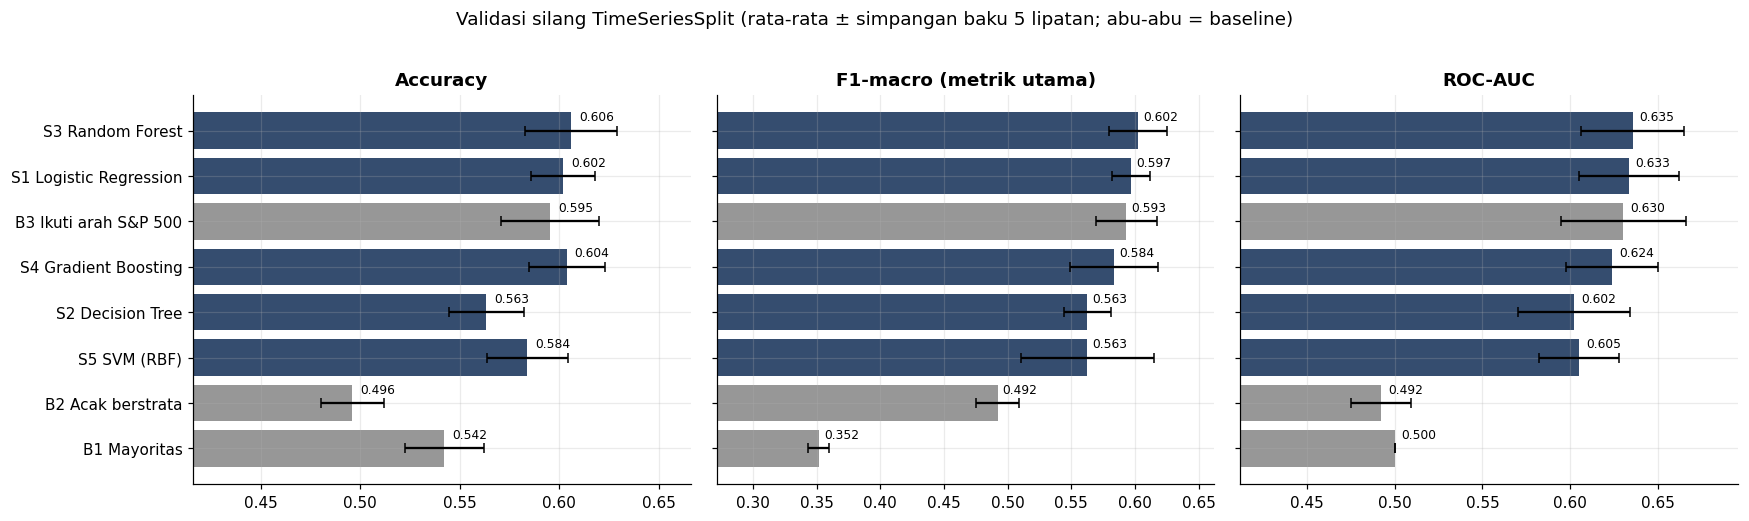

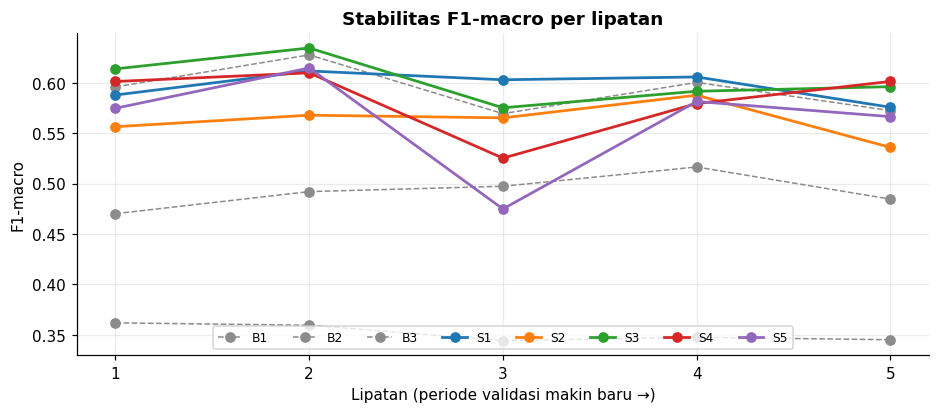

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
order = cvres.sort_values('f1_macro_mean')
labels = order.id + ' ' + order.nama
for ax, (k, title) in zip(axes, [('accuracy', 'Accuracy'), ('f1_macro', 'F1-macro (metrik utama)'), ('roc_auc', 'ROC-AUC')]):
    colors = [C_GREY if j == 'Baseline' else C_NAVY for j in order.jenis]
    ax.barh(labels, order[f'{k}_mean'], xerr=order[f'{k}_std'], color=colors, capsize=3, alpha=0.9)
    lo = max(0.0, order[f'{k}_mean'].min() - 0.08)
    ax.set_xlim(lo, order[f'{k}_mean'].max() + 0.06)
    for i, v in enumerate(order[f'{k}_mean']):
        ax.text(v + 0.004, i + 0.22, f'{v:.3f}', fontsize=8)
    ax.set_title(title)
fig.suptitle('Validasi silang TimeSeriesSplit (rata-rata ± simpangan baku 5 lipatan; abu-abu = baseline)', y=1.02)
plt.tight_layout()
plt.savefig(FIG / '09_cv_comparison.png')
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
for sid, res in per_fold.items():
    style = dict(color=C_GREY, ls='--', lw=1) if sid.startswith('B') else dict(lw=1.8)
    ax.plot(range(1, len(res) + 1), res.f1_macro, marker='o', label=sid, **style)
ax.set_xticks(range(1, cfg['cv']['n_splits'] + 1)); ax.set_xlabel('Lipatan (periode validasi makin baru →)')
ax.set_ylabel('F1-macro'); ax.set_title('Stabilitas F1-macro per lipatan')
ax.legend(ncol=8, fontsize=8, loc='lower center')
plt.savefig(FIG / '09_cv_folds.png')
plt.show()

## 2. Pemilihan skenario terbaik
Aturan dari Unit 8: F1-macro rata-rata tertinggi di antara S1–S5; bila seri, ROC-AUC lebih tinggi.

In [5]:
ranked = cvres[cvres.jenis == 'Model'].sort_values(['f1_macro_mean', 'roc_auc_mean'], ascending=False).reset_index(drop=True)
best = ranked.iloc[0]
b3 = cvres.set_index('id').loc['B3']
display(ranked[['id', 'nama', 'f1_macro_mean', 'roc_auc_mean', 'accuracy_mean']].rename(columns=lambda c: c.replace('_mean', '')))
print(f'Terpilih: {best.id} {best.nama} | F1-macro CV = {best.f1_macro_mean:.3f} ± {best.f1_macro_std:.3f}')
print(f'Pembanding baseline domain B3 (ikuti S&P 500): F1-macro = {b3.f1_macro_mean:.3f}, AUC = {b3.roc_auc_mean:.3f}')

,id,nama,f1_macro,roc_auc,accuracy
0,S3,Random Forest,0.6024,0.6355,0.6061
1,S1,Logistic Regression,0.5969,0.6332,0.6019
2,S4,Gradient Boosting,0.5835,0.6237,0.6038
3,S2,Decision Tree,0.5627,0.6023,0.5634
4,S5,SVM (RBF),0.5625,0.6049,0.5840


Terpilih: S3 Random Forest | F1-macro CV = 0.602 ± 0.023
Pembanding baseline domain B3 (ikuti S&P 500): F1-macro = 0.593, AUC = 0.630


## 3. *Hyperparameter tuning* skenario terpilih (CV yang sama)

In [6]:
spec = next(s for s in cfg['models'] if s['id'] == best.id)
grid = {f'model__{k}': v for k, v in spec['grid'].items()}
gs = GridSearchCV(make_pipeline(spec), grid, cv=tscv, n_jobs=-1,
                  scoring={'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}, refit='f1_macro')
t0 = time.time()
gs.fit(X, y)
print(f'{len(gs.cv_results_["params"])} kombinasi × {tscv.get_n_splits()} lipatan dalam {time.time() - t0:.1f} detik')

gr = pd.DataFrame(gs.cv_results_)
gr = gr[['params', 'mean_test_f1_macro', 'std_test_f1_macro', 'mean_test_roc_auc', 'mean_test_accuracy', 'rank_test_f1_macro']]
gr['params'] = gr.params.map(lambda d: ', '.join(f'{k.replace("model__", "")}={v}' for k, v in d.items()))
display(gr.sort_values('rank_test_f1_macro').head(8).reset_index(drop=True))

best_params = {k.replace('model__', ''): v for k, v in gs.best_params_.items()}
final_params = {**spec['params'], **best_params}
default_f1 = best.f1_macro_mean
print(f'Parameter terbaik: {best_params}')
print(f'F1-macro CV: awal {default_f1:.4f} → setelah tuning {gs.best_score_:.4f} (Δ {gs.best_score_ - default_f1:+.4f})')

9 kombinasi × 5 lipatan dalam 26.0 detik


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_roc_auc,mean_test_accuracy,rank_test_f1_macro
0,"max_depth=8, min_samples_leaf=20",0.6032,0.0200,0.6348,0.6084,1
1,"max_depth=5, min_samples_leaf=20",0.6024,0.0203,0.6355,0.6061,2
2,"max_depth=3, min_samples_leaf=20",0.6001,0.0247,0.6321,0.6038,3
3,"max_depth=8, min_samples_leaf=10",0.5980,0.0206,0.6341,0.6046,4
4,"max_depth=3, min_samples_leaf=10",0.5978,0.0277,0.6319,0.6011,5
5,"max_depth=3, min_samples_leaf=50",0.5975,0.0222,0.6324,0.6004,6
6,"max_depth=5, min_samples_leaf=10",0.5973,0.0224,0.6334,0.6019,7
7,"max_depth=8, min_samples_leaf=50",0.5957,0.0169,0.6339,0.5989,8


Parameter terbaik: {'max_depth': 8, 'min_samples_leaf': 20}
F1-macro CV: awal 0.6024 → setelah tuning 0.6032 (Δ +0.0008)


## 4. Model final dan diagnosis *overfitting*
`GridSearchCV` melatih ulang model dengan parameter terbaik pada **seluruh data latih**. Kinerja pada data latih
dibandingkan dengan kinerja validasi silang: selisih besar menandakan *overfitting*.

In [7]:
final_model = gs.best_estimator_
p_tr = final_model.predict_proba(X)[:, 1]
pred_tr = (p_tr >= 0.5).astype(int)
in_sample = {'accuracy': accuracy_score(y, pred_tr), 'f1_macro': f1_score(y, pred_tr, average='macro'),
             'roc_auc': roc_auc_score(y, p_tr)}
best_idx = gs.best_index_
cv_scores = {'accuracy': gs.cv_results_['mean_test_accuracy'][best_idx],
             'f1_macro': gs.cv_results_['mean_test_f1_macro'][best_idx],
             'roc_auc': gs.cv_results_['mean_test_roc_auc'][best_idx]}
diag = pd.DataFrame({'Data latih (in-sample)': in_sample, 'Validasi silang': cv_scores})
diag['Selisih'] = diag.iloc[:, 0] - diag.iloc[:, 1]
display(diag)
gap = diag.loc['f1_macro', 'Selisih']
verdict = 'wajar (< 0,10)' if gap < 0.10 else 'perlu diwaspadai (≥ 0,10)'
print(f'Selisih F1-macro latih vs CV = {gap:.3f} → {verdict}')

,Data latih (in-sample),Validasi silang,Selisih
accuracy,0.7287,0.6084,0.1203
f1_macro,0.7262,0.6032,0.1230
roc_auc,0.8182,0.6348,0.1834


Selisih F1-macro latih vs CV = 0.123 → perlu diwaspadai (≥ 0,10)


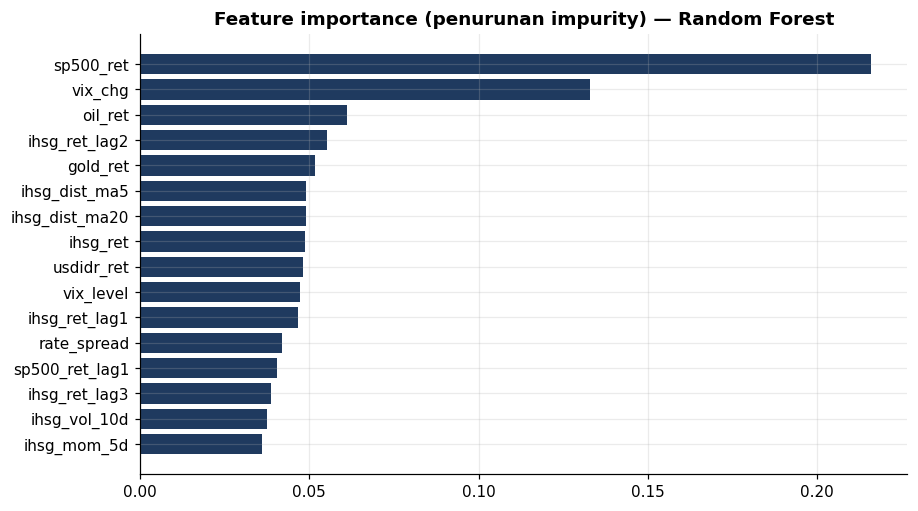

5 fitur teratas: ['sp500_ret', 'vix_chg', 'oil_ret', 'ihsg_ret_lag2', 'gold_ret']


In [8]:
est = final_model.named_steps['model']
if hasattr(est, 'feature_importances_'):
    imp, kind = pd.Series(est.feature_importances_, FEATURES), 'Feature importance (penurunan impurity)'
elif hasattr(est, 'coef_'):
    imp, kind = pd.Series(est.coef_[0], FEATURES), 'Koefisien pada fitur terstandardisasi'
else:
    imp, kind = None, None

if imp is not None:
    imp = imp.reindex(imp.abs().sort_values().index)
    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.barh(imp.index, imp.values, color=[C_NAVY if v >= 0 else C_DOWN for v in imp.values])
    ax.set_title(f'{kind} — {best.nama}')
    plt.savefig(FIG / '09_model_importance.png')
    plt.show()
    print('5 fitur teratas:', list(imp.abs().sort_values(ascending=False).index[:5]))
else:
    print('Model tidak memiliki ukuran kepentingan bawaan; dianalisis dengan permutation importance di Unit 10.')

## 5. Simpan model dan metadata

In [9]:
joblib.dump(final_model, MOD / 'best_model.pkl')
metadata = {
    'model_id': best.id, 'model_name': best.nama, 'estimator': spec['estimator'],
    'pipeline_steps': [name for name, _ in final_model.steps],
    'params': final_params, 'tuned_params': best_params,
    'features': FEATURES, 'threshold': 0.5,
    'cv_default': {k: float(best[f'{k}_mean']) for k in ['accuracy', 'f1_macro', 'roc_auc']},
    'cv_tuned': {k: float(v) for k, v in cv_scores.items()},
    'cv_tuned_f1_std': float(gs.cv_results_['std_test_f1_macro'][best_idx]),
    'cv_baseline_B3': {k: float(b3[f'{k}_mean']) for k in ['accuracy', 'f1_macro', 'roc_auc']},
    'in_sample': in_sample, 'overfit_gap_f1': float(gap),
    'train_period': [f'{train.Date.min():%Y-%m-%d}', f'{train.Date.max():%Y-%m-%d}'], 'n_train': len(train),
    'sklearn_version': sklearn.__version__, 'random_state': RANDOM_STATE,
}
to_json(metadata, MOD / 'model_metadata.json')
display(Markdown(f'''
### Ringkasan Unit 9
- Delapan skenario (3 baseline + 5 model) divalidasi dengan `TimeSeriesSplit` 5 lipatan.
- **Model terpilih: {best.nama}** — F1-macro CV {cv_scores["f1_macro"]:.3f}, ROC-AUC {cv_scores["roc_auc"]:.3f},
  accuracy {cv_scores["accuracy"]:.3f} (setelah tuning: {", ".join(f"{k}={v}" for k, v in best_params.items())}).
- Baseline domain B3 (ikuti S&P 500): F1-macro {b3.f1_macro_mean:.3f}, AUC {b3.roc_auc_mean:.3f}.
- Selisih F1 latih vs CV {gap:.3f} → {verdict}.
- Artefak: `models/best_model.pkl`, `models/model_metadata.json`, `reports/cv_results.csv`.
'''))


### Ringkasan Unit 9
- Delapan skenario (3 baseline + 5 model) divalidasi dengan `TimeSeriesSplit` 5 lipatan.
- **Model terpilih: Random Forest** — F1-macro CV 0.603, ROC-AUC 0.635,
  accuracy 0.608 (setelah tuning: max_depth=8, min_samples_leaf=20).
- Baseline domain B3 (ikuti S&P 500): F1-macro 0.593, AUC 0.630.
- Selisih F1 latih vs CV 0.123 → perlu diwaspadai (≥ 0,10).
- Artefak: `models/best_model.pkl`, `models/model_metadata.json`, `reports/cv_results.csv`.
